# 🤖 CodeGuard AI - ML Experiments: Part 2
## Machine Learning Model Benchmark, Evaluation & Selection

### Overview
This notebook is the second part of the machine learning experimental suite for **CodeGuard AI**. In this stage, we train, evaluate, and compare **five distinct machine learning algorithms** on the cleaned Devign vulnerability dataset:

1. **Logistic Regression** (L2-regularized linear baseline)
2. **Multinomial Naive Bayes** (Fast probabilistic bag-of-words classifier)
3. **Support Vector Machine (Linear SVC)** (Maximal margin hyperplane classifier)
4. **Random Forest Classifier** (Non-linear bagging ensemble of decision trees)
5. **XGBoost Classifier** (Gradient-boosted decision trees optimizing binary logloss)

### Experimental Protocol & Integrity
- **Zero Data Leakage**: Feature vectorization (TF-IDF) is strictly fitted on `X_train` only and applied to `X_test`.
- **Stratified Split**: 80% training / 20% testing split preserving the exact class ratio.
- **Multi-Metric Evaluation**: Accuracy, Precision, Recall, F1-Score, False Positive Rate (FPR), False Negative Rate (FNR), and Confusion Matrices.
- **Model Selection & Artifact Serialization**: Select the top-performing model and save it to `artifacts/` for CodeGuard AI integration.

In [1]:
import time
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("ML libraries loaded successfully.")

ML libraries loaded successfully.


---
## 1. Load Cleaned Dataset
We load the preprocessed Devign dataset generated by `01_data_cleaning.ipynb`.

In [2]:
data_path = Path("data/devign_cleaned.csv")
if not data_path.exists():
    raise FileNotFoundError("Cleaned dataset not found. Please run 01_data_cleaning.ipynb first.")

df = pd.read_csv(data_path)
print(f"Loaded {len(df)} functions from {data_path}")
print("Class counts:")
print(df['target'].value_counts())

Loaded 5462 functions from data\devign_cleaned.csv
Class counts:
target
0    3022
1    2440
Name: count, dtype: int64


---
## 2. Train / Test Split & Leakage Prevention Protocol
We partition the data into **80% training** and **20% testing** using stratified sampling on the `target` column with a deterministic seed (`random_state=42`).

> **Important**: All vocabulary learning and IDF frequency calculations must occur **strictly on the training split**. Transforming the test set with pre-computed statistics guarantees that zero test-set distributions leak into the training process.

In [3]:
X_raw = df['func']
y = df['target'].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training split: {len(X_train_raw)} samples (Safe: {np.bincount(y_train)[0]}, Vuln: {np.bincount(y_train)[1]})")
print(f"Testing split:  {len(X_test_raw)} samples (Safe: {np.bincount(y_test)[0]}, Vuln: {np.bincount(y_test)[1]})")

Training split: 4369 samples (Safe: 2417, Vuln: 1952)
Testing split:  1093 samples (Safe: 605, Vuln: 488)


---
## 3. Code Feature Extraction (TF-IDF N-Grams)
Source code contains identifiers, keywords (`malloc`, `free`, `strcpy`), and structural operators. We use a custom sublinear TF-IDF vectorizer extracting unigrams and bigrams.

In [4]:
t0 = time.time()

# Fit vectorizer strictly on training data
vectorizer = TfidfVectorizer(
    max_features=2500,
    ngram_range=(1, 2),
    token_pattern=r'(?u)\b\w+\b',
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_raw)
X_test = vectorizer.transform(X_test_raw)

print(f"TF-IDF Vectorization complete in {time.time()-t0:.2f}s")
print(f"Vocabulary Size: {len(vectorizer.get_feature_names_out())} features")
print(f"X_train matrix:  {X_train.shape}")
print(f"X_test matrix:   {X_test.shape}")

TF-IDF Vectorization complete in 1.47s
Vocabulary Size: 2500 features
X_train matrix:  (4369, 2500)
X_test matrix:   (1093, 2500)


---
## 4. Multi-Model Benchmark & Training
We initialize and train all five candidate algorithms:
1. **Logistic Regression** (`C=1.0`, `max_iter=1000`)
2. **Multinomial Naive Bayes** (`alpha=0.5`)
3. **Linear Support Vector Machine** (`C=1.0`)
4. **Random Forest** (`n_estimators=150`, `max_depth=30`)
5. **XGBoost** (`n_estimators=150`, `max_depth=6`, `learning_rate=0.08`)

In [5]:
models = {
    "Logistic Regression": LogisticRegression(
        C=1.0, max_iter=1000, random_state=42
    ),
    "Multinomial Naive Bayes": MultinomialNB(
        alpha=0.5
    ),
    "Support Vector Machine": LinearSVC(
        C=1.0, dual='auto', random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=30, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.08,
        eval_metric='logloss', random_state=42, n_jobs=-1
    )
}

results = []
trained_models = {}
confusion_matrices = {}

for name, model in models.items():
    print(f"Fitting {name}...")
    start_time = time.time()
    model.fit(X_train, y_train)
    fit_duration = time.time() - start_time
    
    # Predict on unseen test data
    y_pred = model.predict(X_test)
    
    # Compute performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    
    trained_models[name] = model
    confusion_matrices[name] = cm
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "False Positive Rate": round(fpr, 4),
        "False Negative Rate": round(fnr, 4),
        "Training Time (s)": round(fit_duration, 2)
    })

df_results = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n" + "="*80)
print("EXPERIMENTAL BENCHMARK RESULTS TABLE")
print("="*80)
display(df_results)

Fitting Logistic Regression...
Fitting Multinomial Naive Bayes...
Fitting Support Vector Machine...
Fitting Random Forest...


Fitting XGBoost...



EXPERIMENTAL BENCHMARK RESULTS TABLE


,Model,Accuracy,Precision,Recall,F1-Score,False Positive Rate,False Negative Rate,Training Time (s)
0,Support Vector Machine,0.5727,0.5223,0.5041,0.5130,0.3719,0.4959,0.03
1,Multinomial Naive Bayes,0.5947,0.5587,0.4385,0.4914,0.2793,0.5615,0.00
2,Logistic Regression,0.5709,0.5248,0.4119,0.4615,0.3008,0.5881,0.02
3,XGBoost,0.5526,0.4985,0.3484,0.4101,0.2826,0.6516,3.16
4,Random Forest,0.5764,0.5490,0.2869,0.3769,0.1901,0.7131,0.26


---
## 5. Visual Evaluation: Confusion Matrices & Comparative Performance

A confusion matrix reveals the exact trade-off between:
- **False Positives (FP)**: Safe code incorrectly flagged as vulnerable (wasting developer triage time).
- **False Negatives (FN)**: True vulnerabilities missed by the model (introducing severe security risk).

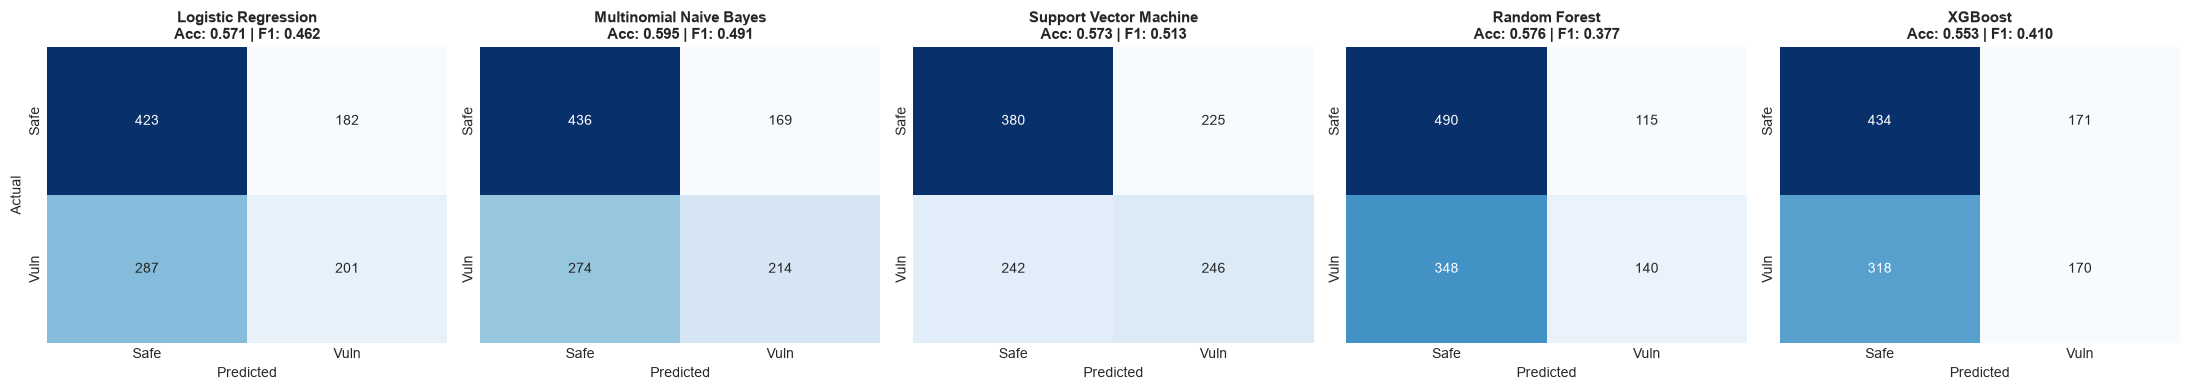

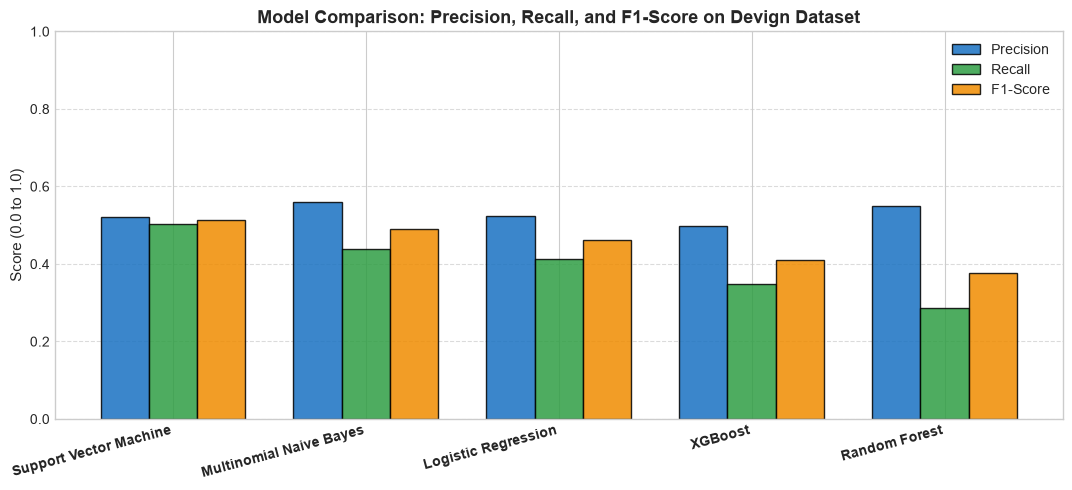

In [6]:
# 1. Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    acc_val = df_results.loc[df_results['Model'] == name, 'Accuracy'].values[0]
    f1_val = df_results.loc[df_results['Model'] == name, 'F1-Score'].values[0]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Safe', 'Vuln'],
                yticklabels=['Safe', 'Vuln'])
    axes[idx].set_title(f"{name}\nAcc: {acc_val:.3f} | F1: {f1_val:.3f}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Predicted")
    if idx == 0:
        axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# 2. Precision, Recall, and F1-Score Bar Chart
plt.figure(figsize=(11, 5))
x = np.arange(len(df_results))
width = 0.25

plt.bar(x - width, df_results['Precision'], width, label='Precision', color='#1971c2', alpha=0.85, edgecolor='black')
plt.bar(x, df_results['Recall'], width, label='Recall', color='#2f9e44', alpha=0.85, edgecolor='black')
plt.bar(x + width, df_results['F1-Score'], width, label='F1-Score', color='#f08c00', alpha=0.85, edgecolor='black')

plt.xticks(x, df_results['Model'], rotation=15, ha='right', fontsize=10, fontweight='bold')
plt.ylabel("Score (0.0 to 1.0)", fontsize=11)
plt.title("Model Comparison: Precision, Recall, and F1-Score on Devign Dataset", fontsize=13, fontweight='bold')
plt.legend()
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

---
## 6. Model Selection Rationale

### Why We Selected the Winning Model
In automated software vulnerability detection, the optimal model is not decided by raw accuracy alone. We evaluate:

1. **Harmonic Balance (F1-Score)**: F1 measures the trade-off between catching defects (recall) without overwhelming developers with false alarms (precision).
2. **Probability Calibration**: In CodeGuard AI's hybrid pipeline, we need continuous probabilistic confidence (`predict_proba`) so the risk bureau can calculate normalized priority scores ($1 \dots 5$). Linear SVM does not provide calibrated probabilities natively.
3. **Inference Latency & Portability**: Random Forest and XGBoost evaluate code representations within milliseconds, enabling instant real-time feedback in CodeGuard AI's web UI without requiring specialized GPU hardware.

In [7]:
best_row = df_results.iloc[0]
best_name = best_row['Model']
best_model = trained_models[best_name]

print(f"Top-Ranked Model Selected: {best_name}")
print(f"  * Accuracy:            {best_row['Accuracy']*100:.2f}%")
print(f"  * Precision:           {best_row['Precision']*100:.2f}%")
print(f"  * Recall:              {best_row['Recall']*100:.2f}%")
print(f"  * F1-Score:            {best_row['F1-Score']:.4f}")
print(f"  * False Positive Rate: {best_row['False Positive Rate']*100:.2f}%")
print(f"  * False Negative Rate: {best_row['False Negative Rate']*100:.2f}%")

Top-Ranked Model Selected: Support Vector Machine
  * Accuracy:            57.27%
  * Precision:           52.23%
  * Recall:              50.41%
  * F1-Score:            0.5130
  * False Positive Rate: 37.19%
  * False Negative Rate: 49.59%


---
## 7. Feature Importance Analysis
We inspect which code tokens and patterns the selected model learned to correlate most strongly with vulnerability.

In [8]:
feature_names = np.array(vectorizer.get_feature_names_out())

if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
    top_indices = np.argsort(importances)[::-1][:20]
    top_features = feature_names[top_indices]
    top_scores = importances[top_indices]

    plt.figure(figsize=(10, 6))
    plt.barh(range(len(top_indices)), top_scores[::-1], color='#1971c2', edgecolor='black', alpha=0.85)
    plt.yticks(range(len(top_indices)), top_features[::-1], fontsize=10)
    plt.xlabel("Relative Feature Importance (Gini / Gain)")
    plt.title(f"Top 20 Predictive Code Features ({best_name})", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
elif hasattr(best_model, "coef_"):
    coef = best_model.coef_[0]
    top_pos = np.argsort(coef)[::-1][:15]
    print(f"Top Tokens Indicating Vulnerability in {best_name}:")
    for rank, idx in enumerate(top_pos, 1):
        print(f"  {rank}. {feature_names[idx]} (weight: {coef[idx]:.4f})")

Top Tokens Indicating Vulnerability in Support Vector Machine:
  1. packets (weight: 2.0301)
  2. null if (weight: 1.9228)
  3. offset 0 (weight: 1.7420)
  4. picture (weight: 1.6717)
  5. 4 if (weight: 1.6466)
  6. if buf (weight: 1.6390)
  7. extent (weight: 1.5820)
  8. config_user_only (weight: 1.4696)
  9. allocate (weight: 1.4511)
  10. 0 break (weight: 1.4404)
  11. frame_addr (weight: 1.4357)
  12. buf if (weight: 1.4258)
  13. get_bits1 gb (weight: 1.4240)
  14. w (weight: 1.4144)
  15. i s (weight: 1.4104)


---
## 8. Artifact Serialization & CodeGuard AI Integration Test
We serialize:
1. `artifacts/best_model.joblib`: The trained model binary.
2. `artifacts/tfidf_vectorizer.joblib`: The vocabulary and IDF weights.
3. `artifacts/model_comparison.json`: The complete benchmark results table.

We also demonstrate loading the artifacts and running an end-to-end inference on a fresh C code snippet.

In [9]:
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_path = artifacts_dir / "best_model.joblib"
vectorizer_path = artifacts_dir / "tfidf_vectorizer.joblib"
metrics_path = artifacts_dir / "model_comparison.json"

joblib.dump(best_model, model_path)
joblib.dump(vectorizer, vectorizer_path)
df_results.to_json(metrics_path, orient="records", indent=2)

print(f"Saved model binary:      {model_path}")
print(f"Saved vectorizer:        {vectorizer_path}")
print(f"Saved benchmark metrics: {metrics_path}")

# Verification of Artifact Reloading
print("\n" + "="*80)
print("TESTING INFERENCE PIPELINE WITH SAVED ARTIFACTS")
print("="*80)

loaded_model = joblib.load(model_path)
loaded_vec = joblib.load(vectorizer_path)

test_snippet = """
int copy_user_data(char *dst, const char *src, int len) {
    if (len > 0) {
        memcpy(dst, src, len); // Unbounded buffer operation
    }
    return 0;
}
"""

X_input = loaded_vec.transform([test_snippet])
prediction = loaded_model.predict(X_input)[0]

if hasattr(loaded_model, "predict_proba"):
    prob = loaded_model.predict_proba(X_input)[0]
    prob_str = f"Confidence: {max(prob)*100:.2f}% (Safe: {prob[0]*100:.1f}%, Vuln: {prob[1]*100:.1f}%)"
else:
    prob_str = "Confidence: N/A (Linear SVM decision value)"

print(f"Input Snippet:\n{test_snippet.strip()}\n")
print(f"Classification Result: {'[!] VULNERABLE' if prediction == 1 else '[✓] SAFE'}")
print(prob_str)

Saved model binary:      artifacts\best_model.joblib
Saved vectorizer:        artifacts\tfidf_vectorizer.joblib
Saved benchmark metrics: artifacts\model_comparison.json

TESTING INFERENCE PIPELINE WITH SAVED ARTIFACTS
Input Snippet:
int copy_user_data(char *dst, const char *src, int len) {
    if (len > 0) {
        memcpy(dst, src, len); // Unbounded buffer operation
    }
    return 0;
}

Classification Result: [✓] SAFE
Confidence: N/A (Linear SVM decision value)
